<a href="https://colab.research.google.com/github/MoeTahech/real-fake-face-detection-thesis/blob/main/notebooks/11_shortcut_confound_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13 — Phase 11: Shortcut / Confound Check

**The question:** Are our models detecting *fake faces*, or are they detecting *which dataset a picture came from*?

**Exam analogy:** imagine a student who passes a "real vs fake" exam by noticing that all fake questions are printed on blue paper and all real ones on white paper. They score 100% without understanding anything. That is a **shortcut**. If our datasets differ in image size, file format or compression between real and fake, a model could use those cues instead of real forgery traces, and our results (including the very high Phase 9 diffusion score) would be less meaningful than they look.

This notebook does three cheap checks. **No model is retrained.**

| Part | What it does | Needs GPU? |
|---|---|---|
| **A. Dataset audit** | Measures size, file format, JPEG compression and sharpness for real vs fake in each test domain | no |
| **B. Metadata-only classifier** | Trains a tiny model that sees **only file facts** (no face content). If it separates real from fake well, a shortcut exists in the data | no |
| **C. Normalization test** | Re-scores your existing P2 / P6 / P9 models after making every image go through the same pipeline (same size, same compression). If the score collapses, the model was leaning on the shortcut | yes (scoring only) |

**How to read the outcome**
- Metadata classifier near 0.5 **and** model scores unchanged by normalization: no shortcut. Your results stand.
- Metadata classifier high **and** model score drops a lot: the model was using the shortcut. That domain's numbers are partly about file format. The fix is to retrain on normalized data (I'd build that next, ~25 min per run).
- Metadata classifier high but model score unchanged: the cue exists in the data, but the model is not relying on it.

**Fair warning:** re-compressing also destroys some genuine forgery traces, so a drop alone is not proof. That is why the notebook has a *resize-only* condition (which touches almost nothing in the 256-pixel datasets) and compares domains against each other.

**Requirements:** notebook 11's Drive folder (`thesis_checkpoints/seed_runs/` with `p2/p6/p9_seed*.pth` and `diffusion_split.json`).

**Estimated time (T4, not measured):** about 15-20 min setup (dataset downloads), A: 3-5 min, B: 1-2 min, C: 10-15 min. Total about 30-45 min.

### Step 1 — GPU and Drive

In [ ]:
!nvidia-smi

Thu Oct 15 10:43:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
CHECKPOINT_DIR = '/content/drive/MyDrive/thesis_checkpoints'
SEED_DIR = f'{CHECKPOINT_DIR}/seed_runs'
SC_DIR   = f'{CHECKPOINT_DIR}/shortcut_check'
os.makedirs(SC_DIR, exist_ok=True)
for need in ['p2_seed0.pth', 'p6_seed0.pth', 'p9_seed0.pth', 'diffusion_split.json']:
    print(('OK      ' if os.path.exists(f'{SEED_DIR}/{need}') else 'MISSING ') + need)

Mounted at /content/drive
OK      p2_seed0.pth
OK      p6_seed0.pth
OK      p9_seed0.pth
OK      diffusion_split.json


### Step 2 — Settings
- `AUDIT_N`: images per class sampled for the audit and metadata classifier.
- `EVAL_N`: images per class per domain used in the normalization test (`None` = all; 2,000 keeps it fast).
- `MODEL_SEEDS`: which seeds of the P2/P6/P9 models to test (scoring is cheap, so all three).
- `JPEG_Q`: the fixed JPEG quality used for the normalized images.

In [ ]:
AUDIT_N = 1500
EVAL_N = 2000
MODEL_SEEDS = [0, 1, 2]
JPEG_Q = 75
RESIZE_TO = 256
N_BOOT = 500

### Step 3 — Kaggle access and datasets

In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = "YOUR_KAGGLE_API_HERE"

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d xhlulu/140k-real-and-fake-faces
!unzip -q 140k-real-and-fake-faces.zip -d data_raw
!kaggle datasets download -d manjilkarki/deepfake-and-real-images
!unzip -q deepfake-and-real-images.zip -d data_raw_2
!kaggle datasets download -d bwandowando/faces-dataset-using-stable-diffusion-v14
!unzip -q faces-dataset-using-stable-diffusion-v14.zip -d data_diffusion
print("All three datasets downloaded.")

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [00:32<00:00, 125MB/s]

Dataset URL: https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images
License(s): unknown
100% 1.68G/1.68G [00:11<00:00, 160MB/s]

Dataset URL: https://www.kaggle.com/datasets/bwandowando/faces-dataset-using-stable-diffusion-v14
License(s): CC0-1.0
100% 1.10G/1.10G [00:15<00:00, 74.5MB/s]

All three datasets downloaded.


### Step 4 — Rebuild the three evaluation sets (identical to notebooks 11 and 12)

In [ ]:
import os, random, json
import numpy as np

def find_real_fake_folders(root):
    out = []
    for dp, dn, _ in os.walk(root):
        low = [d.lower() for d in dn]
        if "real" in low and "fake" in low: out.append(dp)
    return out
def find_split(root, kw):
    c = find_real_fake_folders(root); m = [x for x in c if kw in x.lower()]
    if not m: raise FileNotFoundError(f"No folder containing '{kw}' under {root}. Found: {c}")
    return m[0]
def find_class_dir(split_root, cls):
    for d in os.listdir(split_root):
        if d.lower() == cls: return os.path.join(split_root, d)
    raise FileNotFoundError(f"No '{cls}' folder in {split_root}")
def link(src, dst):
    if not os.path.exists(dst): os.symlink(os.path.abspath(src), dst)

styleGAN_test = find_split("data_raw", "test")
faceswap_test = find_split("data_raw_2", "test")
SPLIT_FILE = f"{SEED_DIR}/diffusion_split.json"
if not os.path.exists(SPLIT_FILE): raise FileNotFoundError("diffusion_split.json not found. Run notebook 11 first.")
sp = json.load(open(SPLIT_FILE))
diffusion_heldout_images = [os.path.join("data_diffusion", p) for p in sp["heldout"]]

def build_eval_subset(source_root, dst_root, n_per_class, seed=99):
    rng = random.Random(seed)
    for cls in ["real", "fake"]:
        os.makedirs(f"{dst_root}/{cls}", exist_ok=True)
        cd = find_class_dir(source_root, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
        for f in files[:n_per_class]: link(os.path.join(cd, f), f"{dst_root}/{cls}/{f}")
def build_eval_diffusion(dst_root, fake_paths, real_dir, seed=7):
    rng = random.Random(seed)
    os.makedirs(f"{dst_root}/fake", exist_ok=True); os.makedirs(f"{dst_root}/real", exist_ok=True)
    reals = sorted(os.listdir(real_dir)); rng.shuffle(reals); reals = reals[:len(fake_paths)]
    for i, p in enumerate(sorted(fake_paths)): link(p, f"{dst_root}/fake/{i}_{os.path.basename(p)}")
    for i, f in enumerate(reals):              link(os.path.join(real_dir, f), f"{dst_root}/real/{i}_{f}")

build_eval_subset(styleGAN_test, "eval_stylegan", 5000)
build_eval_subset(faceswap_test, "eval_faceswap", 5000)
build_eval_diffusion("eval_diffusion", diffusion_heldout_images, find_class_dir(styleGAN_test, "real"))
EVAL_SETS = {"stylegan": "eval_stylegan", "faceswap": "eval_faceswap", "diffusion": "eval_diffusion"}
for k, v in EVAL_SETS.items(): print(k, {c: len(os.listdir(f"{v}/{c}")) for c in ["real", "fake"]})

stylegan {'real': 5000, 'fake': 5000}
faceswap {'real': 5000, 'fake': 5000}
diffusion {'real': 1015, 'fake': 1015}


## Part A — Dataset audit (no model)

For every sampled image we record the facts a model should *not* need: width, height, file size, bytes per pixel, JPEG or not, JPEG quantization level (a **lower** `qtable_mean` means **higher** quality), and three simple pixel statistics measured at the size the model sees (224x224): brightness, contrast, and sharpness (variance of the Laplacian).

In [ ]:
from PIL import Image
from scipy.ndimage import laplace
import pandas as pd

def audit_dir(root, domain, n_per_class, seed=0):
    rng = random.Random(seed); rows = []
    for cls in ["real", "fake"]:
        files = sorted(os.listdir(f"{root}/{cls}")); rng.shuffle(files)
        for f in files[:n_per_class]:
            p = os.path.realpath(f"{root}/{cls}/{f}")
            with Image.open(p) as im:
                w, h = im.size; fmt = im.format
                qmean = float(np.mean(im.quantization[0])) if fmt == "JPEG" and getattr(im, "quantization", None) else 0.0
                g = np.asarray(im.convert("L").resize((224, 224), Image.BILINEAR), dtype=np.float32)
            kb = os.path.getsize(p) / 1024
            rows.append({"domain": domain, "label": 1 if cls == "fake" else 0, "cls": cls, "format": fmt, "width": w, "height": h,
                         "file_kb": kb, "bytes_per_pixel": kb * 1024 / (w * h), "is_jpeg": int(fmt == "JPEG"), "qtable_mean": qmean,
                         "brightness": g.mean(), "contrast": g.std(), "sharpness": float(laplace(g).var())})
    return pd.DataFrame(rows)

AUD = pd.concat([audit_dir(v, k, AUDIT_N) for k, v in EVAL_SETS.items()], ignore_index=True)
AUD.to_csv(f"{SC_DIR}/audit_per_image.csv", index=False)
summary = (AUD.groupby(["domain", "cls"]).agg(n=("width", "size"), format=("format", lambda s: s.value_counts().to_dict()),
            width_median=("width", "median"), height_median=("height", "median"), file_kb_median=("file_kb", "median"),
            bytes_per_pixel=("bytes_per_pixel", "median"), qtable_mean=("qtable_mean", "median"), sharpness_median=("sharpness", "median")).round(3))
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
print(summary.to_string())
summary.to_csv(f"{SC_DIR}/audit_summary.csv")

                   n          format  width_median  height_median  file_kb_median  bytes_per_pixel  qtable_mean  sharpness_median
domain    cls                                                                                                                    
diffusion fake  1015   {'PNG': 1015}         512.0          512.0         459.049            1.793        0.000           516.747
          real  1015  {'JPEG': 1015}         256.0          256.0          28.055            0.438        5.766           345.057
faceswap  fake  1500  {'JPEG': 1500}         256.0          256.0           9.986            0.156       29.031           211.654
          real  1500  {'JPEG': 1500}         256.0          256.0           9.793            0.153       29.031           195.782
stylegan  fake  1500  {'JPEG': 1500}         256.0          256.0          27.342            0.427        5.766           296.986
          real  1500  {'JPEG': 1500}         256.0          256.0          28.128         

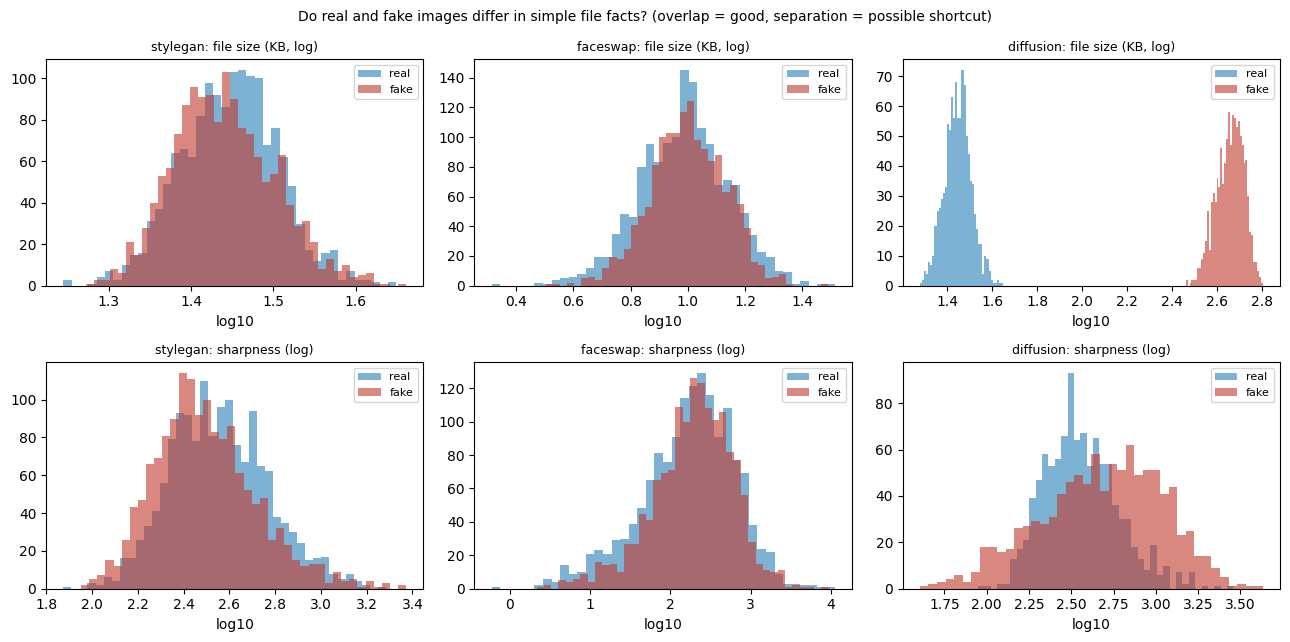

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for j, d in enumerate(EVAL_SETS):
    sub = AUD[AUD.domain == d]
    for r, (col, lab) in enumerate([("file_kb", "file size (KB, log)"), ("sharpness", "sharpness (log)")]):
        ax = axes[r, j]
        for cls, c in [("real", "#2980b9"), ("fake", "#c0392b")]:
            v = np.log10(sub[sub.cls == cls][col].clip(lower=1e-3)); ax.hist(v, bins=40, alpha=.6, color=c, label=cls)
        ax.set_title(f"{d}: {lab}", fontsize=9); ax.set_xlabel("log10"); ax.legend(fontsize=8)
plt.suptitle("Do real and fake images differ in simple file facts? (overlap = good, separation = possible shortcut)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{SC_DIR}/audit_histograms.png", dpi=200); plt.show()

## Part B — Metadata-only classifier (no face content at all)

A small gradient-boosting model sees **only** the file facts and tries to predict real vs fake (5-fold cross-validated AUC, so it is tested on images it did not train on). Three versions: file metadata only, pixel statistics only, and both.

**0.5 = the facts carry no information (good). Close to 1.0 = a shortcut exists in the data.**

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

META = ["width", "height", "file_kb", "bytes_per_pixel", "is_jpeg", "qtable_mean"]
PIX  = ["brightness", "contrast", "sharpness"]
rows = []
for d in EVAL_SETS:
    sub = AUD[AUD.domain == d]; y = sub["label"].values
    cv = StratifiedKFold(5, shuffle=True, random_state=0)
    res = {"domain": d}
    for name, feats in [("metadata_only", META), ("pixel_stats_only", PIX), ("both", META + PIX)]:
        clf = HistGradientBoostingClassifier(max_iter=100, random_state=0)
        p = cross_val_predict(clf, sub[feats].values, y, cv=cv, method="predict_proba")[:, 1]
        res[name] = roc_auc_score(y, p)
    uni = {f: roc_auc_score(y, sub[f].values) for f in META + PIX}
    best = max(uni, key=lambda f: abs(uni[f] - .5)); res["strongest_single_feature"] = f"{best} (AUC {max(uni[best], 1 - uni[best]):.3f})"
    rows.append(res)
tb = pd.DataFrame(rows); print(tb.round(3).to_string(index=False))
tb.to_csv(f"{SC_DIR}/metadata_classifier_auc.csv", index=False)

   domain  metadata_only  pixel_stats_only  both strongest_single_feature
 stylegan          0.539             0.558 0.609    sharpness (AUC 0.588)
 faceswap          0.535             0.541 0.544     contrast (AUC 0.550)
diffusion          1.000             0.793 1.000        width (AUC 1.000)


## Part C — Normalization test on your existing models

Every image in each evaluation set is pushed through the **same** pipeline, and the P2 / P6 / P9 models (all seeds, no retraining) are scored again:

| Condition | What is done to every image (real and fake) | What it removes |
|---|---|---|
| `original` | nothing | (baseline) |
| `resize256` | resize to 256x256 (bicubic) | size differences. The 256-pixel datasets are almost untouched, so this isolates resolution |
| `jpeg75` | re-encode as JPEG, quality 75 | format and compression differences |
| `resize256_jpeg75` | both | all of the above |

The same images are used in all four conditions, so differences are due to the pipeline only.

In [ ]:
import io, torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
std_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), normalize])

class CondLoader:
    def __init__(self, cond): self.cond = cond
    def __call__(self, path):
        im = Image.open(path).convert("RGB")
        if "resize256" in self.cond: im = im.resize((RESIZE_TO, RESIZE_TO), Image.BICUBIC)
        if "jpeg75" in self.cond:
            buf = io.BytesIO(); im.save(buf, format="JPEG", quality=JPEG_Q); buf.seek(0); im = Image.open(buf).convert("RGB")
        return im
CONDITIONS = ["original", "resize256", "jpeg75", "resize256_jpeg75"]

def load_resnet(path):
    ck = torch.load(path, map_location=device)
    m = models.resnet18(weights=None); m.fc = nn.Linear(m.fc.in_features, 2)
    m.load_state_dict(ck["model_state"]); m.to(device).eval()
    return m, ck["class_to_idx"]

MODELS = {}
for s in MODEL_SEEDS:
    for m in ["p2", "p6", "p9"]:
        path = f"{SEED_DIR}/{m}_seed{s}.pth"
        if os.path.exists(path): MODELS[f"{m}_seed{s}"] = load_resnet(path)
print("Loaded models:", list(MODELS))

Loaded models: ['p2_seed0', 'p6_seed0', 'p9_seed0', 'p2_seed1', 'p6_seed1', 'p9_seed1', 'p2_seed2', 'p6_seed2', 'p9_seed2']


In [ ]:
@torch.no_grad()
def score_condition(domain, cond, n_per_class=EVAL_N, seed=0):
    ds = datasets.ImageFolder(EVAL_SETS[domain], transform=std_transform, loader=CondLoader(cond))
    rng = np.random.default_rng(seed); idx = []
    for c in range(len(ds.classes)):
        ci_ = [i for i, t in enumerate(ds.targets) if t == c]
        idx += list(rng.choice(ci_, min(len(ci_), n_per_class), replace=False)) if n_per_class else ci_
    idx = sorted(int(i) for i in idx)
    loader = DataLoader(Subset(ds, idx), batch_size=128, shuffle=False, num_workers=2)
    labels = np.array([ds.targets[i] for i in idx]); names = ds.classes
    probs = {t: [] for t in MODELS}
    for x, _ in loader:
        x = x.to(device)
        for t, (m, cidx) in MODELS.items(): probs[t].append(torch.softmax(m(x), 1)[:, cidx["real"]].cpu().numpy())
    out = {}
    for t, (m, cidx) in MODELS.items():
        is_real = np.array([names[l].lower() == "real" for l in labels]); out[t] = (is_real, np.concatenate(probs[t]))
    return out

import time
RES = {}   # (cond, domain) -> {model_tag: (is_real, p_real)}
for cond in CONDITIONS:
    for d in EVAL_SETS:
        t0 = time.time(); RES[(cond, d)] = score_condition(d, cond)
        print(f"{cond:18s} {d:10s} done in {time.time() - t0:5.1f}s")

original           stylegan   done in  34.7s
original           faceswap   done in  32.6s
original           diffusion  done in  22.3s
resize256          stylegan   done in  33.0s
resize256          faceswap   done in  33.2s
resize256          diffusion  done in  24.3s
jpeg75             stylegan   done in  34.1s
jpeg75             faceswap   done in  34.1s
jpeg75             diffusion  done in  24.5s
resize256_jpeg75   stylegan   done in  34.2s
resize256_jpeg75   faceswap   done in  34.3s
resize256_jpeg75   diffusion  done in  25.9s


In [ ]:
rows = []
for (cond, d), per_model in RES.items():
    for tag, (r, p) in per_model.items():
        rows.append({"condition": cond, "domain": d, "model": tag.split("_")[0], "seed": int(tag.split("seed")[1]),
                     "auc": roc_auc_score(r, p), "acc": ((p >= .5) == r).mean()})
R = pd.DataFrame(rows); R.to_csv(f"{SC_DIR}/normalization_per_run.csv", index=False)
sd = lambda x: x.std(ddof=1) if len(x) > 1 else float("nan")
agg = R.groupby(["model", "domain", "condition"]).agg(auc_mean=("auc", "mean"), auc_std=("auc", sd), acc_mean=("acc", "mean")).reset_index()
piv = agg.pivot_table(index=["model", "domain"], columns="condition", values="auc_mean")[CONDITIONS]
piv["drop_resize"] = piv["resize256"] - piv["original"]; piv["drop_jpeg"] = piv["jpeg75"] - piv["original"]; piv["drop_both"] = piv["resize256_jpeg75"] - piv["original"]
print("=== Mean AUC over seeds, by condition (drop_* = condition minus original) ===")
print(piv.round(3).to_string())
agg.to_csv(f"{SC_DIR}/normalization_summary.csv", index=False)

=== Mean AUC over seeds, by condition (drop_* = condition minus original) ===
condition        original  resize256  jpeg75  resize256_jpeg75  drop_resize  drop_jpeg  drop_both
model domain                                                                                     
p2    diffusion     0.305      0.318   0.265             0.304        0.013     -0.040     -0.000
      faceswap      0.505      0.505   0.505             0.505        0.000      0.001      0.001
      stylegan      0.999      0.999   0.997             0.997        0.000     -0.002     -0.002
p6    diffusion     0.629      0.652   0.488             0.676        0.023     -0.141      0.047
      faceswap      0.898      0.898   0.898             0.898        0.000      0.000      0.000
      stylegan      0.996      0.996   0.991             0.991        0.000     -0.005     -0.005
p9    diffusion     0.999      0.998   0.997             0.993       -0.000     -0.002     -0.006
      faceswap      0.920      0.920   0

In [ ]:
# Paired bootstrap on the drop (seed 0, same images in both conditions)
from scipy.stats import rankdata
def auc_fast(pos, neg):
    n1, n0 = len(pos), len(neg); r = rankdata(np.concatenate([pos, neg]))
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def drop_ci(r, p_orig, p_cond, n_boot=N_BOOT, seed=0):
    rng = np.random.default_rng(seed); ip, ineg = np.where(r)[0], np.where(~r)[0]; ds_ = np.empty(n_boot)
    for b in range(n_boot):
        bp, bn = rng.choice(ip, len(ip)), rng.choice(ineg, len(ineg))
        ds_[b] = auc_fast(p_cond[bp], p_cond[bn]) - auc_fast(p_orig[bp], p_orig[bn])
    return ds_.mean(), *np.percentile(ds_, [2.5, 97.5])
rows = []
for d in EVAL_SETS:
    for m in ["p2", "p6", "p9"]:
        tag = f"{m}_seed0"
        if tag not in MODELS: continue
        r, p0 = RES[("original", d)][tag]
        for cond in CONDITIONS[1:]:
            r2, p1 = RES[(cond, d)][tag]; assert np.array_equal(r, r2)
            mu, lo, hi = drop_ci(r, p0, p1)
            rows.append({"model": m, "domain": d, "condition": cond, "auc_original": roc_auc_score(r, p0), "auc_condition": roc_auc_score(r, p1),
                         "change": mu, "ci_lo": lo, "ci_hi": hi, "verdict": "CHANGED (CI excludes 0)" if (lo > 0 or hi < 0) else "no detectable change"})
DB = pd.DataFrame(rows); print("=== Paired bootstrap on the AUC change (seed 0) ===")
print(DB.round(4).to_string(index=False)); DB.to_csv(f"{SC_DIR}/normalization_bootstrap_seed0.csv", index=False)

=== Paired bootstrap on the AUC change (seed 0) ===
model    domain        condition  auc_original  auc_condition  change   ci_lo   ci_hi                 verdict
   p2  stylegan        resize256        0.9993         0.9993  0.0000  0.0000  0.0000    no detectable change
   p2  stylegan           jpeg75        0.9993         0.9978 -0.0015 -0.0022 -0.0010 CHANGED (CI excludes 0)
   p2  stylegan resize256_jpeg75        0.9993         0.9978 -0.0015 -0.0022 -0.0010 CHANGED (CI excludes 0)
   p6  stylegan        resize256        0.9959         0.9959  0.0000  0.0000  0.0000    no detectable change
   p6  stylegan           jpeg75        0.9959         0.9920 -0.0039 -0.0052 -0.0028 CHANGED (CI excludes 0)
   p6  stylegan resize256_jpeg75        0.9959         0.9920 -0.0039 -0.0052 -0.0028 CHANGED (CI excludes 0)
   p9  stylegan        resize256        0.9951         0.9951  0.0000  0.0000  0.0000    no detectable change
   p9  stylegan           jpeg75        0.9951         0.9916 -0.003

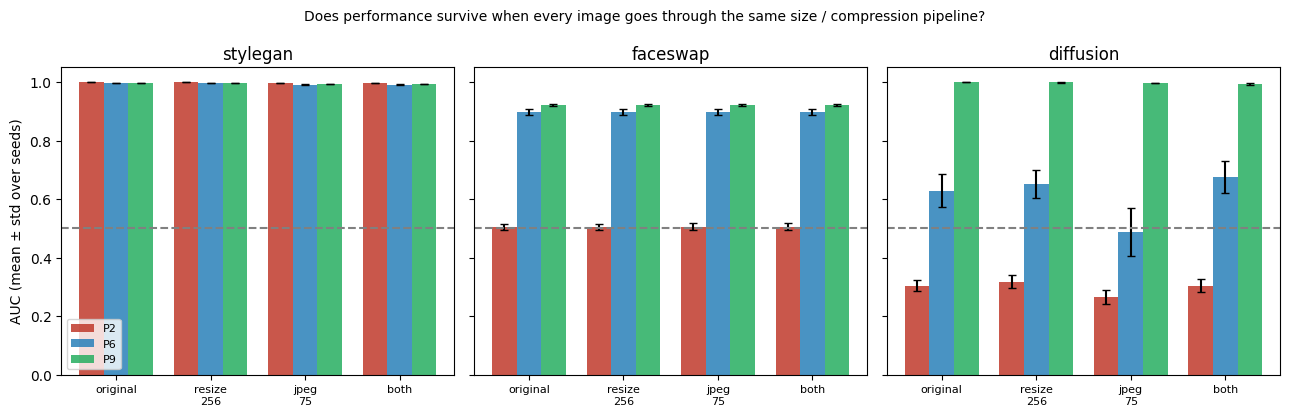

Saved everything to /content/drive/MyDrive/thesis_checkpoints/shortcut_check


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True); cols = {"p2": "#c0392b", "p6": "#2980b9", "p9": "#27ae60"}; w = 0.26
for ax, d in zip(axes, EVAL_SETS):
    for j, m in enumerate(["p2", "p6", "p9"]):
        sub = agg[(agg.model == m) & (agg.domain == d)].set_index("condition").reindex(CONDITIONS)
        xs = np.arange(len(CONDITIONS)) + (j - 1) * w
        ax.bar(xs, sub.auc_mean, w, yerr=sub.auc_std.fillna(0), capsize=3, color=cols[m], alpha=.85, label=m.upper())
    ax.axhline(.5, ls="--", c="gray"); ax.set_xticks(range(len(CONDITIONS))); ax.set_xticklabels(["original", "resize\n256", "jpeg\n75", "both"], fontsize=8)
    ax.set_title(d); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("AUC (mean ± std over seeds)"); axes[0].legend(fontsize=8)
plt.suptitle("Does performance survive when every image goes through the same size / compression pipeline?", fontsize=10)
plt.tight_layout(); plt.savefig(f"{SC_DIR}/normalization_barplot.png", dpi=200); plt.show()
print("Saved everything to", SC_DIR)

## How to read the results (before sending them to me)

1. **Part A / B:** for each domain, is there a big difference between real and fake in file size, format, size or compression? Is the metadata-only AUC far from 0.5?
2. **Part C:** for each model and domain, does AUC fall a lot under `resize256`, `jpeg75`, or both? Compare **domains**: if the 256-pixel datasets barely move but diffusion collapses, the diffusion score was partly a format/size shortcut.
3. Look at **P2 on diffusion** (AUC about 0.3, below chance). If normalization pushes it toward 0.5, the below-chance behavior was driven by file/format cues. If it stays below 0.5, it is something about the images themselves.

**Please send back** the executed notebook. If Part C shows a big drop, the next step is retraining on normalized data to see how much real signal remains.